# Simulation Study

In [1]:
from preamble import *

%config InlineBackend.figure_format = 'retina'


In [2]:
# dill.load_session("Sim_Poisson_Depexp.pkl")

In [3]:
import sys

print("ABC version:", abc.__version__)
print("Python version:", sys.version)
print("Numpy version:", np.__version__)
print("PyMC3 version:", pm.__version__)
print("Arviz version:", arviz.__version__)

tic()

ABC version: 0.2.1
Python version: 3.8.20 (default, Oct  3 2024, 15:24:27) 
[GCC 11.2.0]
Numpy version: 1.22.3
PyMC3 version: 3.11.4
Arviz version: 0.12.1


In [4]:
numIters = numItersData = 10
popSize = 1000
smcArgs = {"verbose": True, "numProcs": 40}

## Inference of a Poison- Frequency Dependent Exponential model

In this notebook we are are conducting a simulation experiment where the claim frequency are Negative Binomial distributed 

$$
n_s\underset{\textbf{i.i.d.}}{\sim}\text{Pois}(\lambda = 5),\text{ }s = 1,\ldots, 30
$$ 

and the individual claim sizes are freqency dependent exponential which means that 

$$
u_1,\ldots, u_{n_s}|n_s\underset{\textbf{i.i.d.}}{\sim}\text{Exp}(\beta\times e^{\delta n_s}),\text{ }s = 1,\ldots 30,
$$ 
where we set $\beta = 2$ and $\delta = 0.2$.

The available data is the total claim sizes, we have 

$$
x_s = \sum_{k = 1}^{n_s}u_k,\text{ }s = 1,\ldots, t.
$$

Our aim is to see if ABC is able to fit this model featuring dependency between claim counts and claim frequency. 

In [5]:
rg = default_rng(123)

sample_sizes = [50, 250]
T = sample_sizes[-1]
t = np.arange(1, T + 1, 1)

# Frequency-Loss Model
λ, β, δ = 4, 2, 0.2
θ_True = λ, β, δ
θ_sev = β, δ
θ_freq = λ
sev = "frequency dependent exponential"
freq = "poisson"

# Aggregation process
psi = abc.Psi("sum")

freqs, sevs = abc.simulate_claim_data(rg, T, freq, sev, θ_True)
df_full = pd.DataFrame(
    {
        "time_period": np.concatenate([np.repeat(s, freqs[s - 1]) for s in t]),
        "claim_size": sevs,
        "N": np.concatenate([np.repeat(freqs[s - 1], freqs[s - 1]) for s in t]),
    }
)

xData = abc.compute_psi(freqs, sevs, psi)

df_agg = pd.DataFrame({"time_period": t, "N": freqs, "X": xData})

In [6]:
[np.sum(xData[:ss] > 0) for ss in sample_sizes]

[47, 245]

## True posterior samples

We run a Bayesian analysis on the individual claim data and frequency data so as to infer the parameters of the Poisson and dependent exponential distribution. The prior distribution on the parameters are taken as independent uniform distribution (as in the ABC approach). 

### Fitting a dependent exponential model to the individual loss data

In [7]:
dfsev = pd.DataFrame({"ss": [], "β": [], "δ": []})

for ss in sample_sizes:

    fullData = df_full[df_full.time_period <= ss]
    print("The number of individual claim sizes is ", len(fullData))
    with pm.Model() as model:

        # Weakly informative priors,
        β = pm.Uniform("β", lower=0, upper=10)
        δ = pm.Uniform("δ", lower=-1, upper=1)

        # Poisson likelihood
        u = pm.Exponential(
            "u",
            lam=np.exp(-δ * fullData["N"].values) / β,
            observed=fullData["claim_size"].values,
        )
        %time trace = pm.sample_smc(popSize, random_seed=134, chains = 1)
        res = pd.DataFrame(
            {
                "ss": np.repeat(ss, popSize),
                "β": trace["β"],
                "δ": trace["δ"],
            }
        )

    dfsev = pd.concat([dfsev, res])

The number of individual claim sizes is  178


Initializing SMC sampler...
Sampling 1 chain in 1 job
Stage:   0 Beta: 0.003
Stage:   1 Beta: 0.020
Stage:   2 Beta: 0.072
Stage:   3 Beta: 0.208
Stage:   4 Beta: 0.675
Stage:   5 Beta: 1.000


CPU times: user 2.74 s, sys: 275 ms, total: 3.02 s
Wall time: 12.1 s
The number of individual claim sizes is  1017


Initializing SMC sampler...
Sampling 1 chain in 1 job
Stage:   0 Beta: 0.000
Stage:   1 Beta: 0.003
Stage:   2 Beta: 0.013
Stage:   3 Beta: 0.039
Stage:   4 Beta: 0.125
Stage:   5 Beta: 0.399
Stage:   6 Beta: 1.000


CPU times: user 3.13 s, sys: 21.8 ms, total: 3.15 s
Wall time: 3.19 s


### Fitting a Poisson model to the claim frequency data

Initializing SMC sampler...
Sampling 1 chain in 1 job
Stage:   0 Beta: 0.037
Stage:   1 Beta: 0.271
Stage:   2 Beta: 1.000


CPU times: user 985 ms, sys: 55.3 ms, total: 1.04 s
Wall time: 4.12 s


/home/spacenut/miniconda3/envs/sem8/lib/python3.8/site-packages/arviz/utils.py:187: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  numba_fn = numba.jit(**self.kwargs)(self.function)
Initializing SMC sampler...
Sampling 1 chain in 1 job
Stage:   0 Beta: 0.008
Stage:   1 Beta: 0.062
Stage:   2 Beta: 0.474
Stage:   3 Beta: 1.000


CPU times: user 997 ms, sys: 2.75 ms, total: 999 ms
Wall time: 1 s


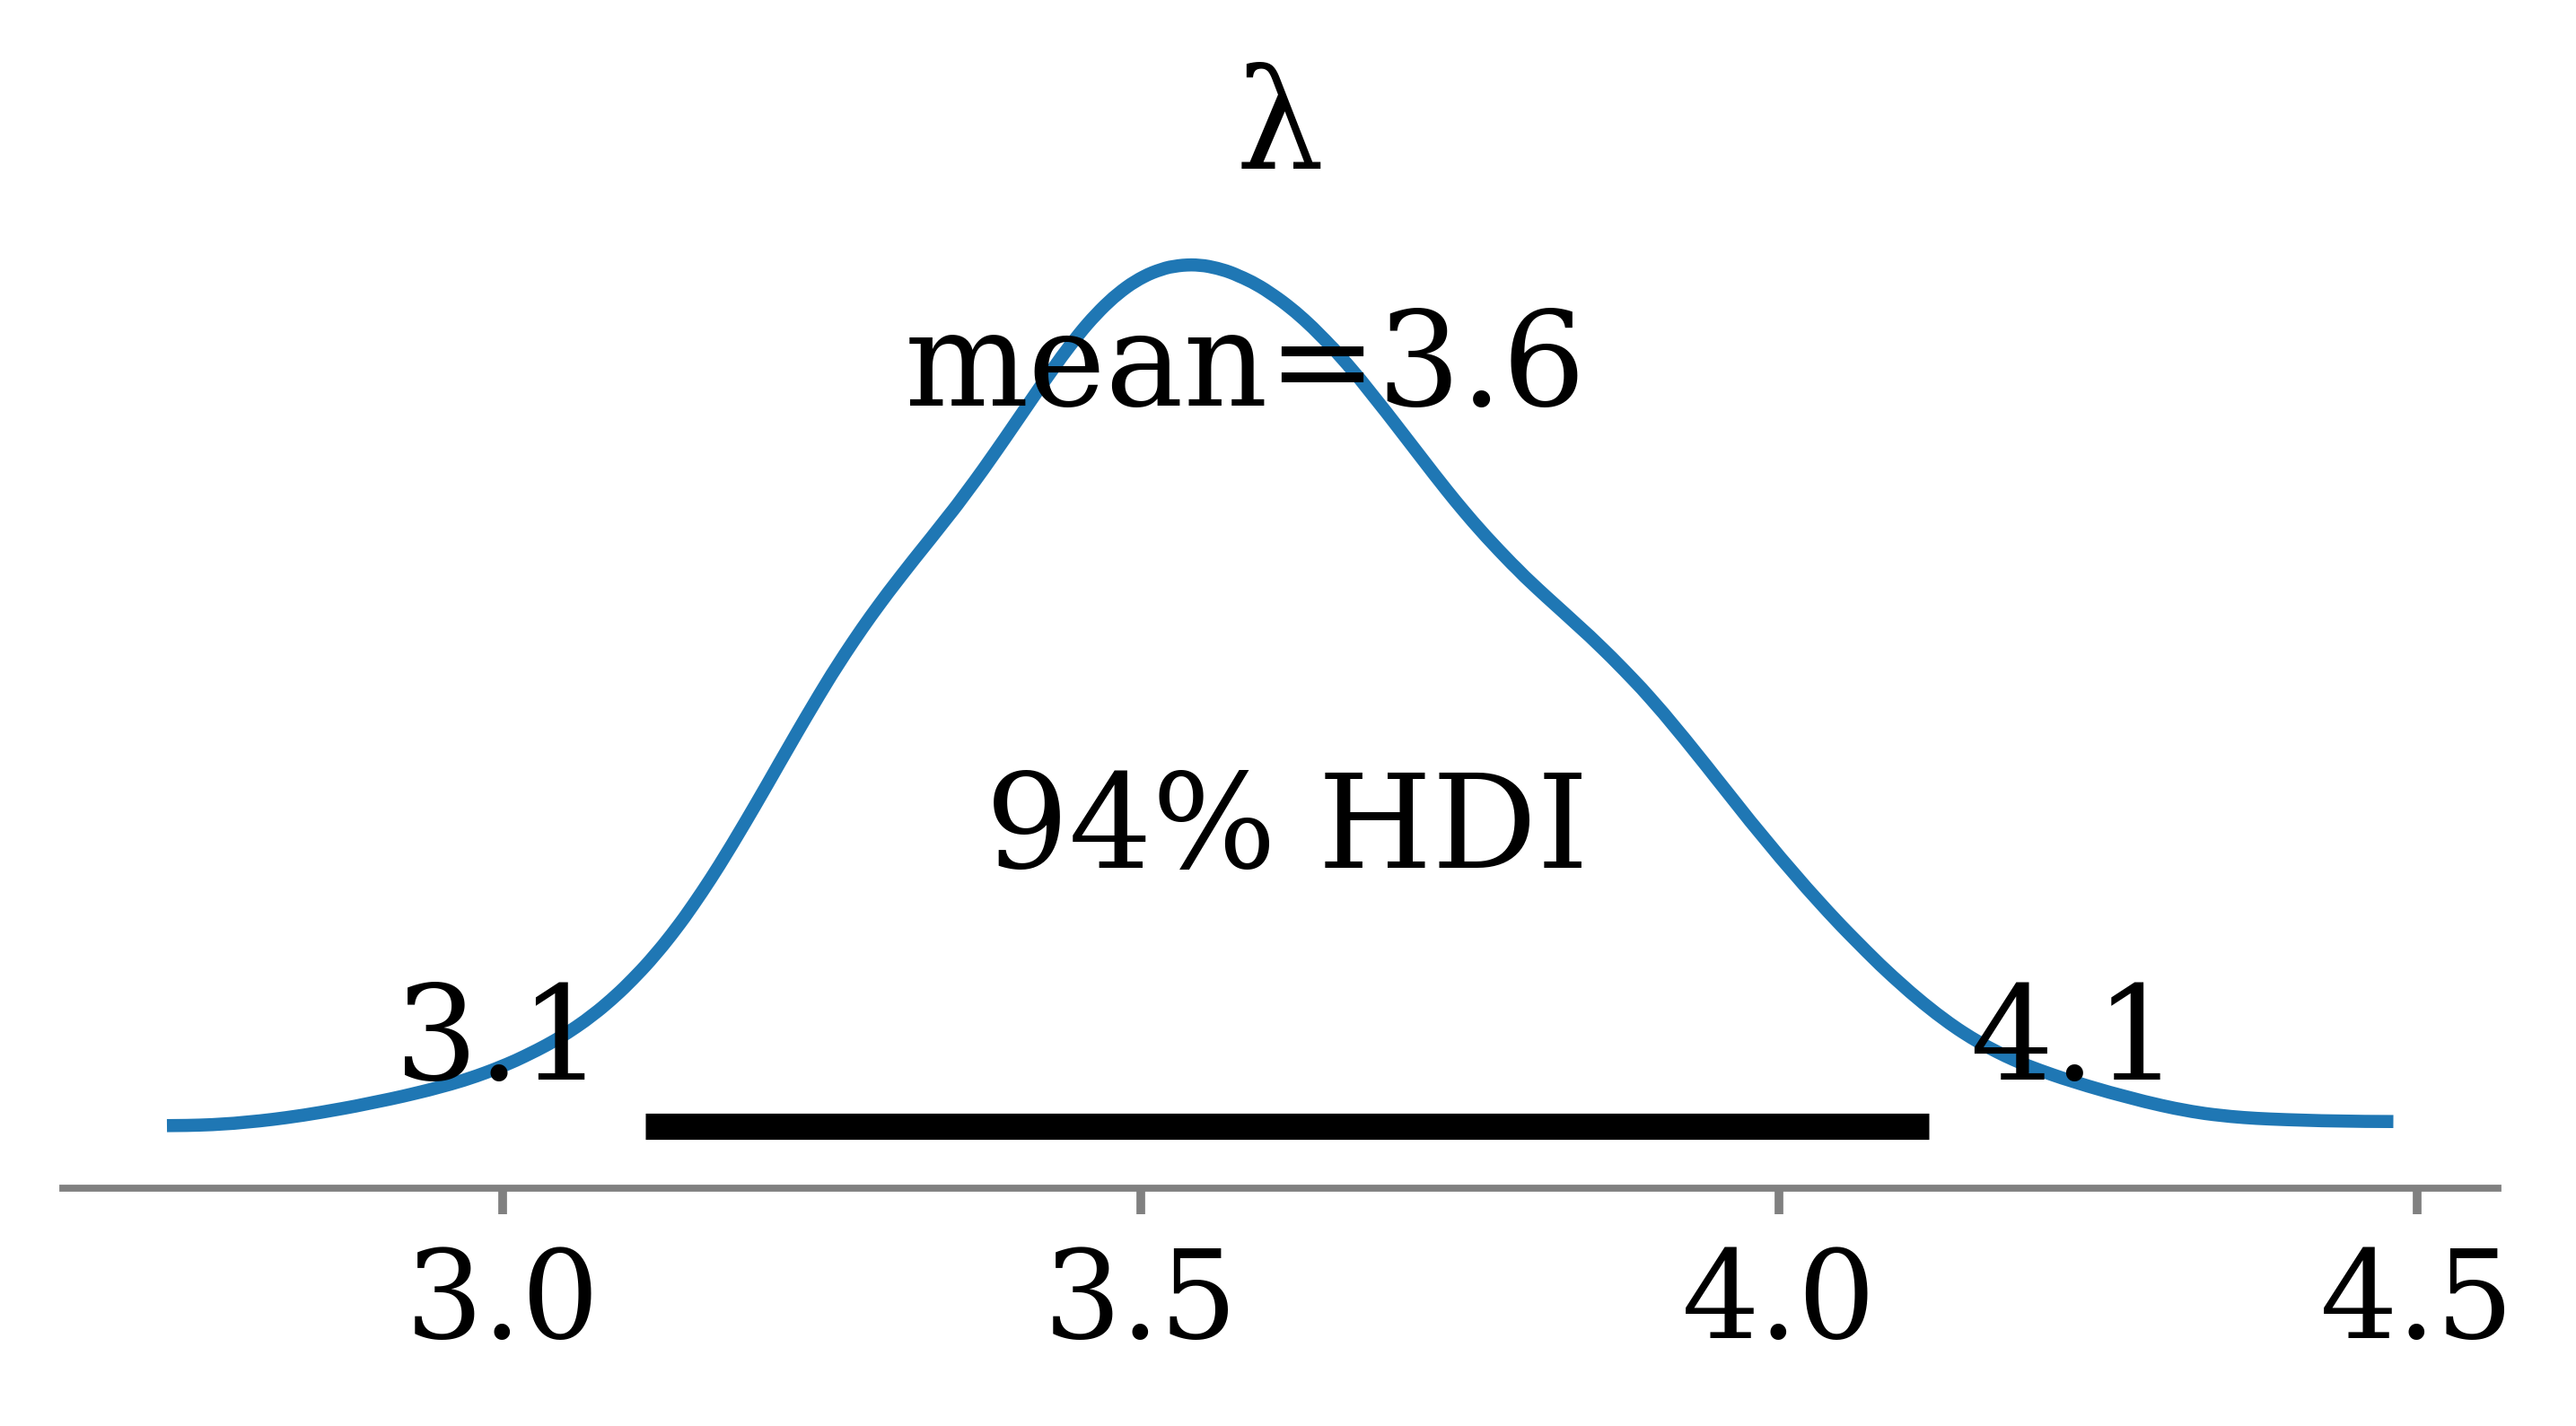

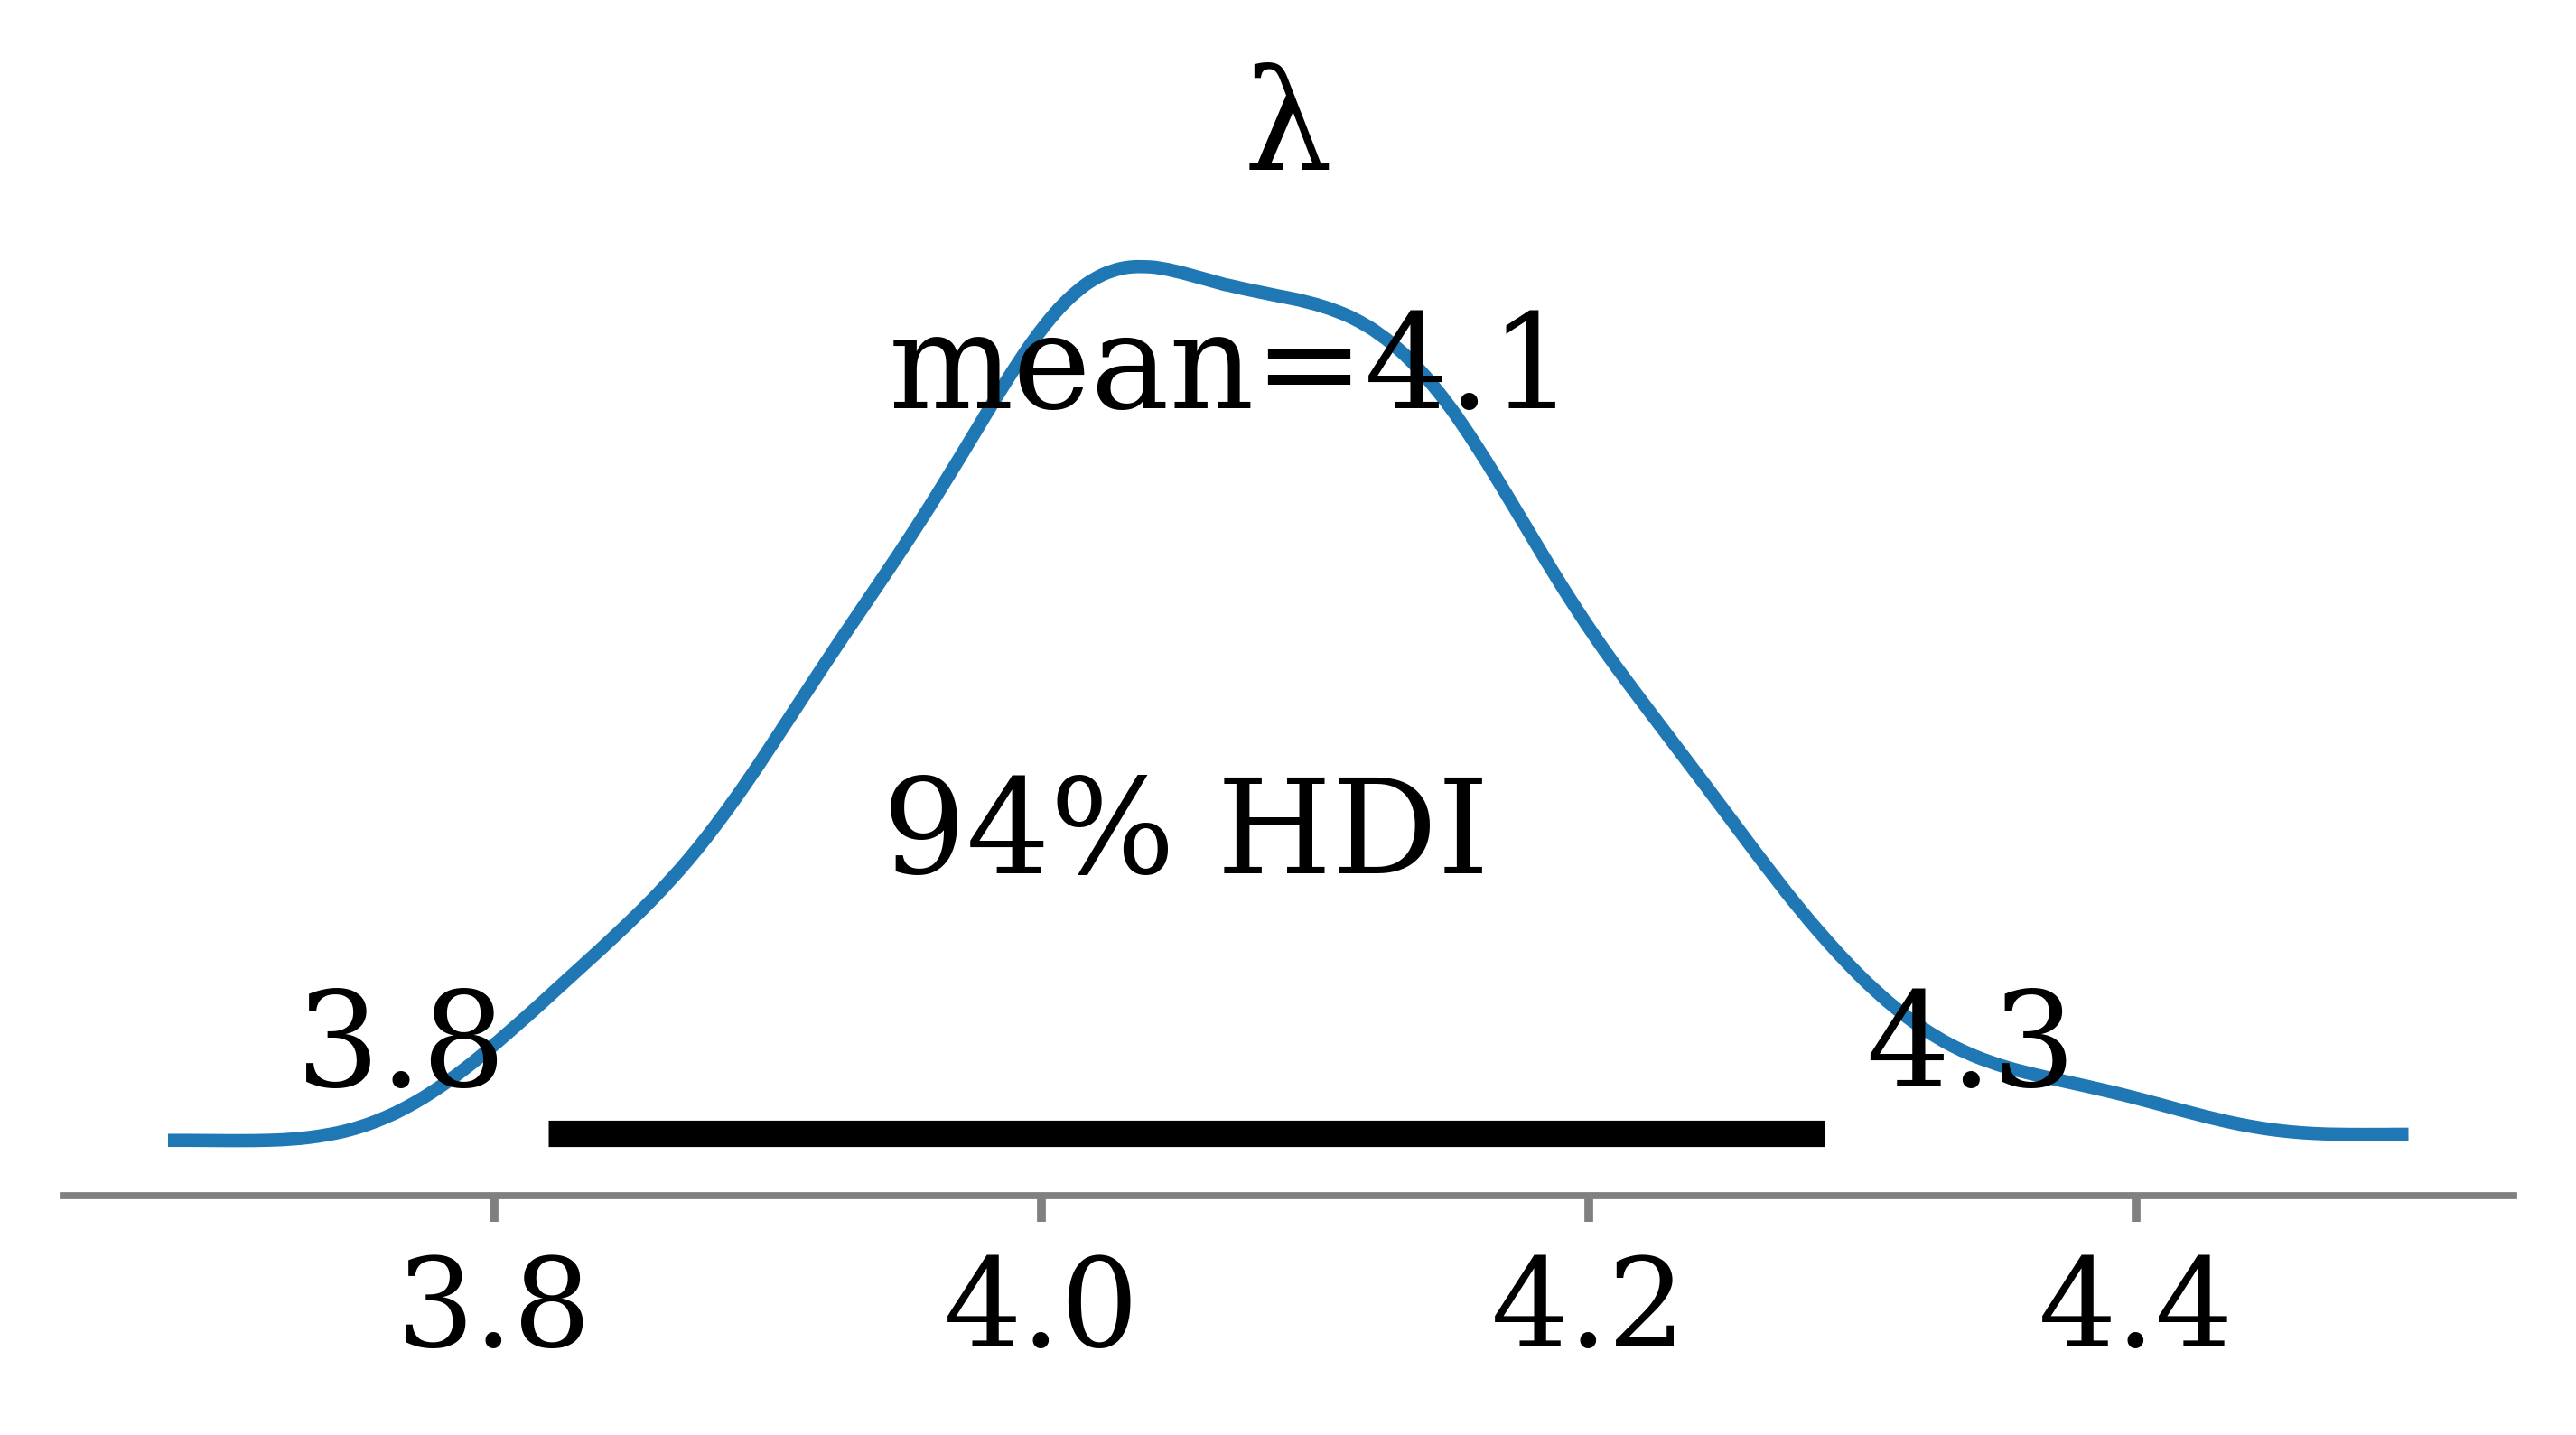

In [8]:
dffreq = pd.DataFrame({"ss": [], "λ": []})

for ss in sample_sizes:
    nData = df_agg.N[df_agg.time_period <= ss]
    with pm.Model() as model_negbin:
        λ = pm.Uniform("λ", lower=0, upper=10)
        N = pm.Poisson("N", mu=λ, observed=nData)

        %time trace = pm.sample_smc(popSize, random_seed=1, chains = 1)
        arviz.plot_posterior(trace)

    res = pd.DataFrame({"ss": np.repeat(ss, popSize), "λ": trace["λ"]})
    dffreq = pd.concat([dffreq, res])

We store all the posterior samples in one single data frame

In [9]:
dftrue = pd.concat([dffreq, dfsev.drop("ss", axis=1)], axis=1)
dftrue["posterior"] = np.repeat("True", len(dftrue))

## ABC posterior for the Poisson - frequency dependent exponential model

In [10]:
params = ("λ", "β", "δ")
prior = abc.IndependentUniformPrior([(0, 10), (0, 20), (-1, 1)], params)
model = abc.Model("poisson", "frequency dependent exponential", psi, prior)

In [11]:
dfABC = pd.DataFrame({"ss": [], "weights": [], "λ": [], "β": [], "δ": []})

for ss in sample_sizes:
    xDataSS = df_agg.X[df_agg.time_period <= ss].to_numpy()

    %time fit = abc.smc(numIters, popSize, xDataSS, model, priors=prior, **smcArgs)

    res = pd.DataFrame(
        {
            "ss": np.repeat(ss, popSize),
            "weights": fit.weights,
            "λ": fit.samples[:, 0],
            "β": fit.samples[:, 1],
            "δ": fit.samples[:, 2],
        }
    )

    dfABC = pd.concat([dfABC, res])

Starting ABC-SMC with population size of 1000 and sample size of 50 (~> 50) on 40 processes.
Finished sampling from prior, eps = 18.69, time = 121.0s / 2.0m, popSize = 1000 -> 500, ESS = 1000 -> 500, # sims = 1000, total # sims = 1000
Finished SMC iteration 1, eps = 12.80, time = 27.0s / 0.5m, popSize = 1544 -> 529, ESS = 1449 -> 500, # sims = 4160, total # sims = 5160
Finished SMC iteration 2, eps = 8.69, time = 1.0s / 0.0m, popSize = 1556 -> 545, ESS = 1385 -> 500, # sims = 6920, total # sims = 12080
Finished SMC iteration 3, eps = 6.69, time = 2.0s / 0.0m, popSize = 1570 -> 649, ESS = 1226 -> 500, # sims = 9560, total # sims = 21640
Finished SMC iteration 4, eps = 5.26, time = 2.0s / 0.0m, popSize = 1693 -> 570, ESS = 1296 -> 500, # sims = 16040, total # sims = 37680
Finished SMC iteration 5, eps = 4.56, time = 4.0s / 0.1m, popSize = 1583 -> 615, ESS = 1013 -> 500, # sims = 27520, total # sims = 65200
Finished SMC iteration 6, eps = 3.96, time = 7.0s / 0.1m, popSize = 1676 -> 628, E

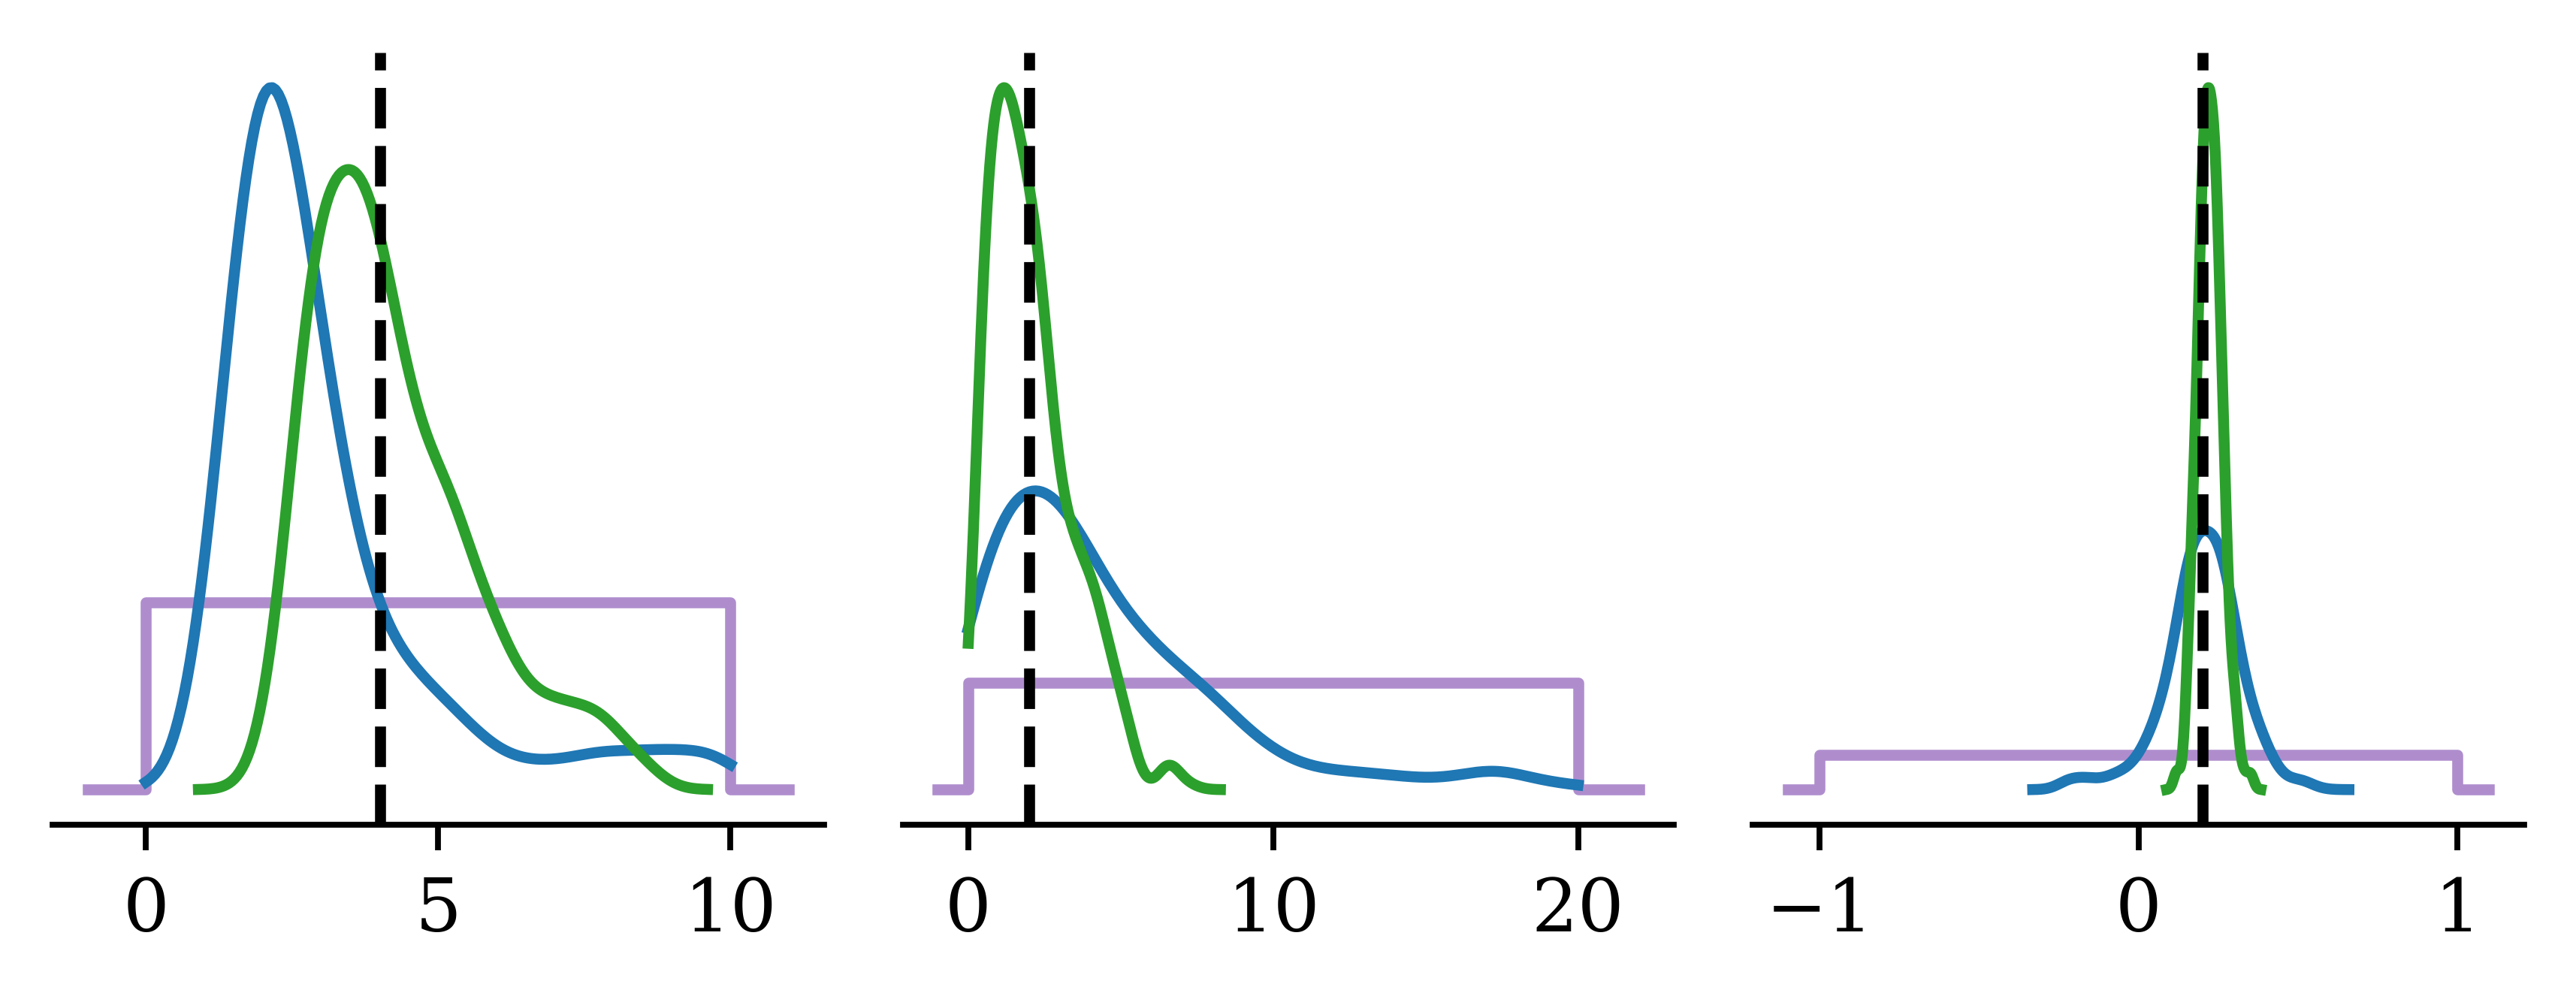

In [12]:
fig, axs = plt.subplots(1, len(params), tight_layout=True)

for l in range(len(params)):
    pLims = [prior.marginals[l].isf(1), prior.marginals[l].isf(0)]
    # axs[l].set_xlim(pLims)

    for k, ss in enumerate(sample_sizes):
        sampleData = dfABC.query("ss == @ss")
        sample = sampleData[params[l]]
        weights = sampleData["weights"]

        dataResampled, xs, ys = abc.resample_and_kde(sample, weights, clip=pLims)
        axs[l].plot(xs, ys, label="ABC")

    axs[l].axvline(θ_True[l], **trueStyle)
    # axs[l].set_title("$" + params + "$")
    axs[l].set_yticks([])

draw_prior(prior, axs)
sns.despine(left=True)
# save_cropped("../Figures/hist-test2-poisson-depexp.pdf")

In [13]:
params = ("λ", "β", "δ")
paramsTex = ("\\lambda", "\\beta", "\\delta")

/tmp/ipykernel_12130/163418932.py:15: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(
/tmp/ipykernel_12130/163418932.py:15: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(
/tmp/ipykernel_12130/163418932.py:15: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.

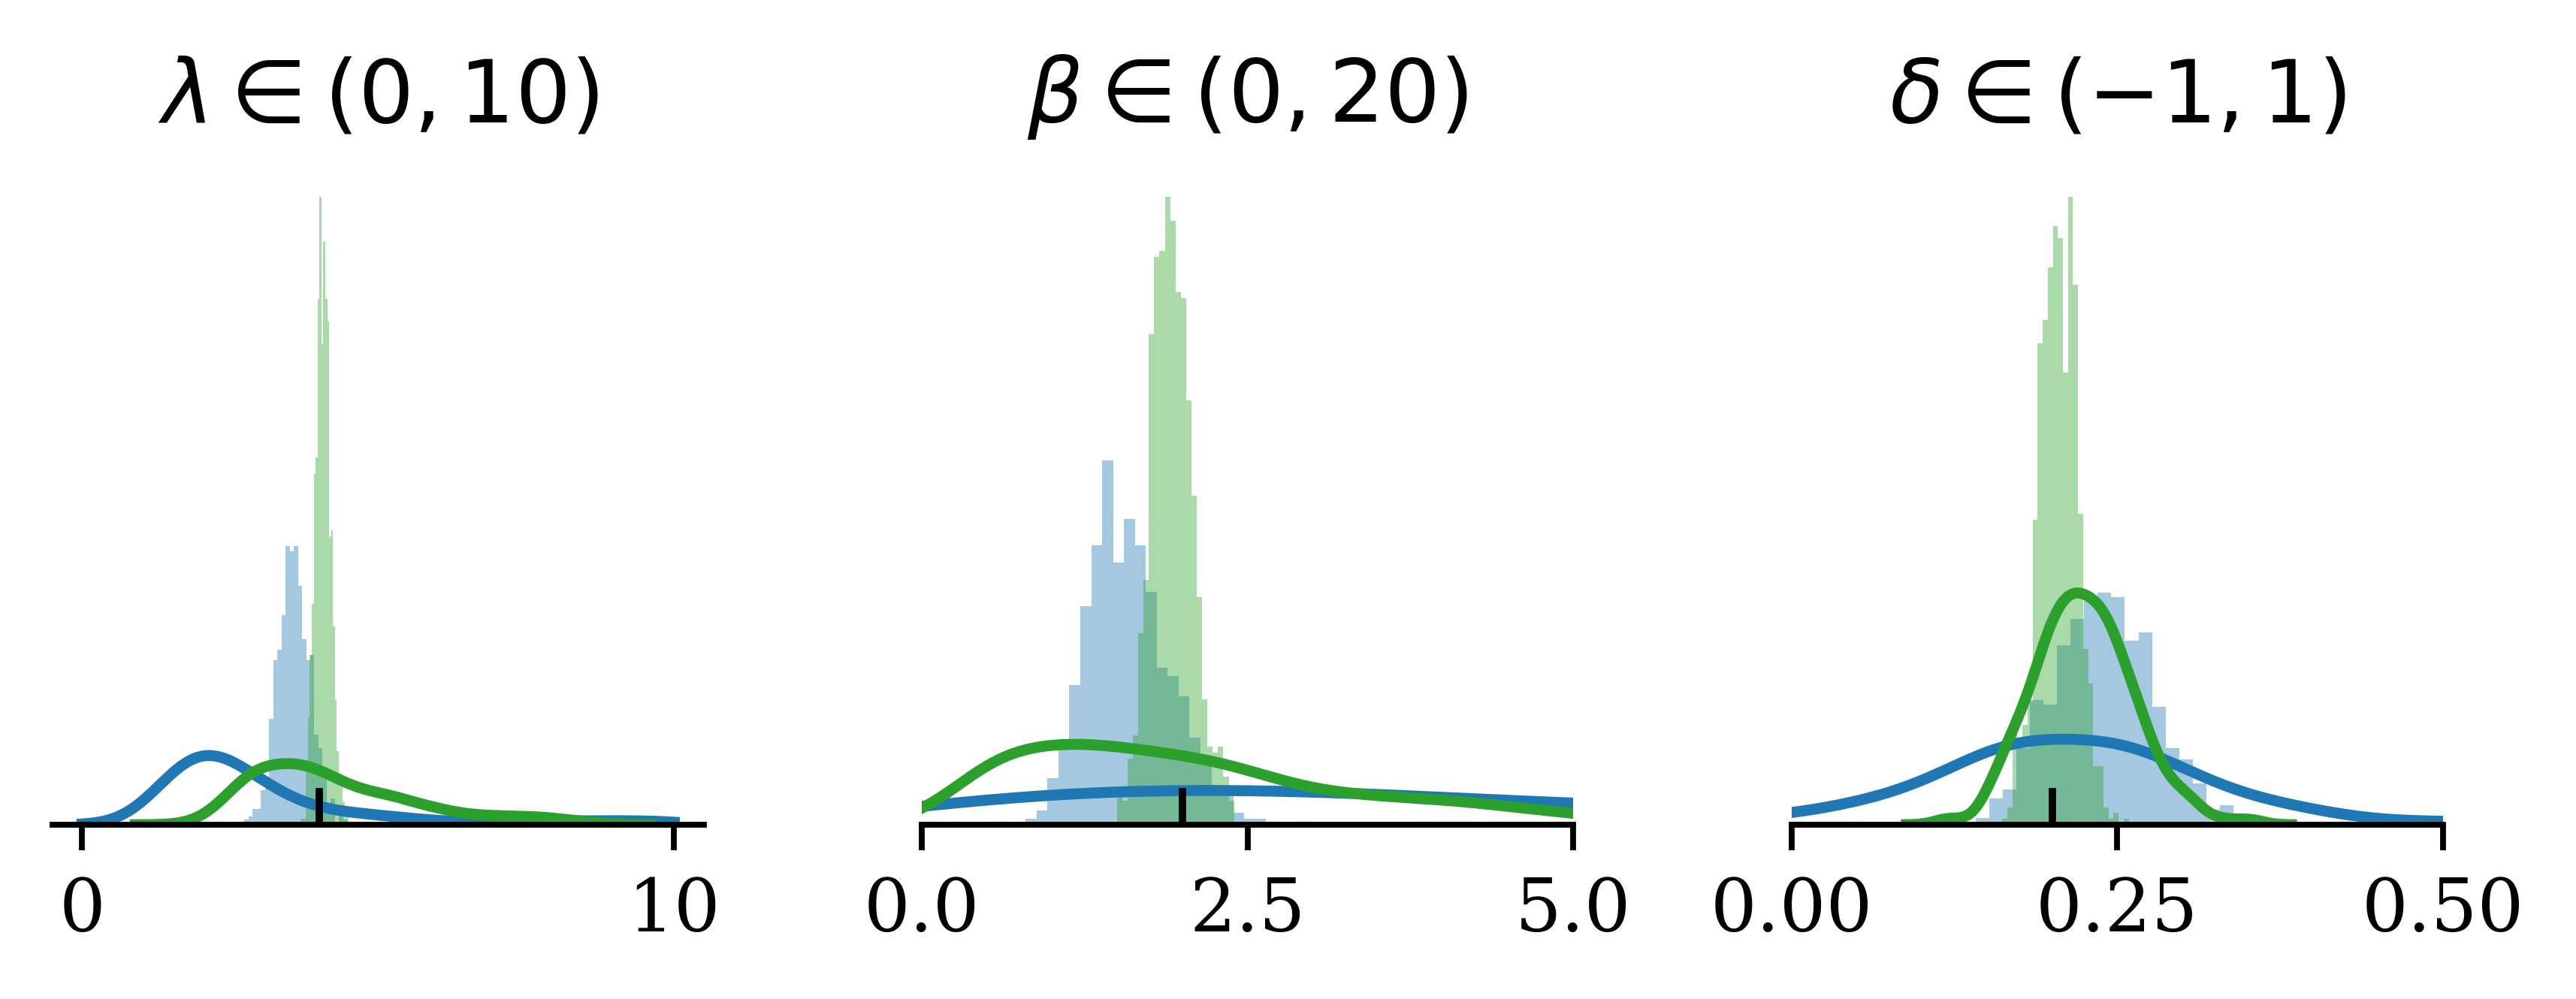

In [14]:
fig, axs = plt.subplots(1, len(params), tight_layout=True)

for l, param in enumerate(params):
    pLims = [prior.marginals[l].isf(1), prior.marginals[l].isf(0)]
    # axs[l].set_xlim(pLims)

    for k, ss in enumerate(sample_sizes):
        sampleData = dfABC.query("ss == @ss")
        sample = sampleData[params[l]]
        weights = sampleData["weights"]

        dataResampled, xs, ys = abc.resample_and_kde(sample, weights, clip=pLims)
        axs[l].plot(xs, ys, label="ABC")

        sns.distplot(
            dftrue.query("ss == @ss")[param],
            color=colors[k],
            ax=axs[l],
            kde=False,
            hist_kws={"density": True},
        )

    # axs[l].axvline(θ_True[l], **trueStyle)
    axs[l].plot(θ_True[l], 0, color="k", marker="|", markersize=10)
    axs[l].set_title("$" + paramsTex[l] + f"\\in ({pLims[0]:.0f}, {pLims[1]:.0f})$")
    axs[l].set_yticks([])
    axs[l].set_xlabel("")

axs[1].set_xlim([0, 5])
axs[2].set_xlim([0, 0.5])

sns.despine(left=True)
# save_cropped("../Figures-Slides/hist-test2-poisson-depexp-approximate.pdf")

/tmp/ipykernel_12130/2562527689.py:29: UserWarning: The figure layout has changed to tight
  plt.tight_layout(pad=0.0)
/tmp/ipykernel_12130/2562527689.py:29: UserWarning: The figure layout has changed to tight
  plt.tight_layout(pad=0.0)


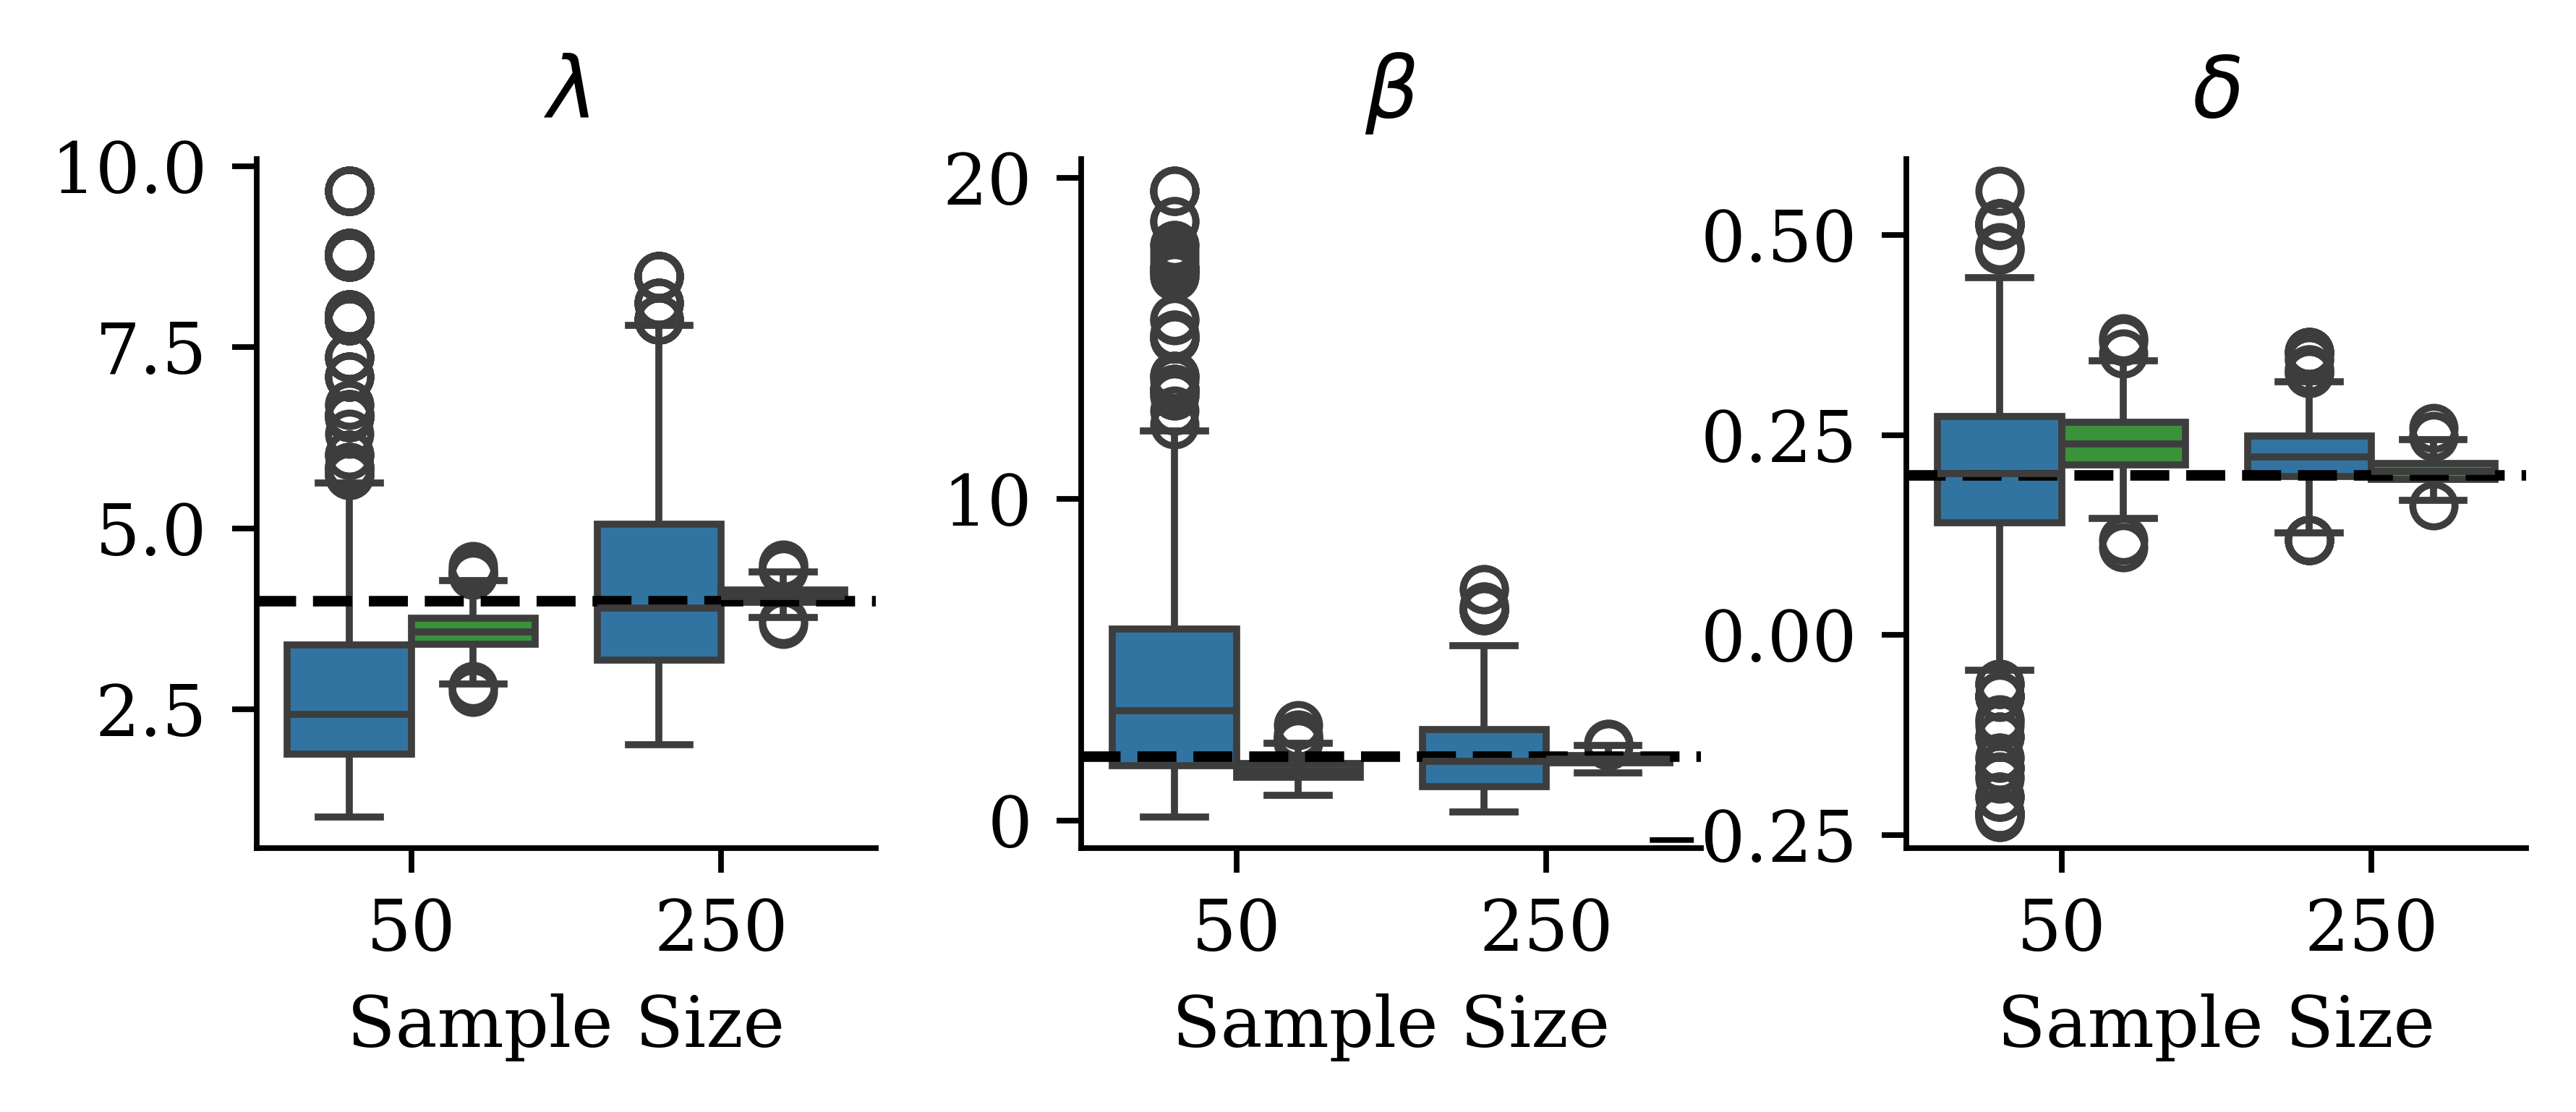

In [15]:
rg = default_rng(1)

n_resample = 1
resampled_post_ABC = pd.DataFrame(
    {"ss": np.concatenate([np.repeat(ss, popSize * n_resample) for ss in sample_sizes])}
)

for l in range(len(params)):
    res_param = np.array([])
    for ss in sample_sizes:
        sampleData = dfABC.query("ss == @ss")
        sample = sampleData[params[l]]
        weights = sampleData["weights"]

        dataResampled = sample[abc.resample(rg, weights, repeats=n_resample)]
        res_param = np.concatenate([res_param, dataResampled])

    resampled_post_ABC[params[l]] = res_param

resampled_post_ABC["posterior"] = np.repeat(
    "ABC", len(sample_sizes) * popSize * n_resample
)
post_samples = pd.concat([resampled_post_ABC, dftrue], axis=0)

post_samples["ss"] = post_samples["ss"].astype(np.int64)

for l in range(len(params)):
    plt.subplot(1, len(params), l + 1)
    plt.tight_layout(pad=0.0)
    g = sns.boxplot(x="ss", y=params[l], hue="posterior", data=post_samples)
    plt.gca().axhline(θ_True[l], **trueStyle)
    plt.title("$" + params[l] + "$")
    plt.ylabel("")
    plt.xlabel("Sample Size")
    plt.legend("", frameon=False)

sns.despine()
# save_cropped("../Figures/boxplot-test2-poisson-depexp.pdf")

## ABC posterior for the dependent exponential parameters with the claim frequency

In [16]:
params = ("β", "δ")
prior = abc.IndependentUniformPrior([(0, 20), (-1, 1)], params)

In [17]:
dfABC_freq = pd.DataFrame({"ss": [], "weights": [], "β": [], "δ": []})

for ss in sample_sizes:
    xDataSS = df_agg.X[df_agg.time_period <= ss].to_numpy()
    nData = np.array(df_agg.N[df_agg.time_period <= ss])

    model = abc.Model(nData, "frequency dependent exponential", psi, prior)

    %time fit = abc.smc(numItersData, popSize, xDataSS, model,priors=prior, **smcArgs)

    res = pd.DataFrame(
        {
            "ss": np.repeat(ss, popSize),
            "weights": fit.weights,
            "β": fit.samples[:, 0],
            "δ": fit.samples[:, 1],
        }
    )

    dfABC_freq = pd.concat([dfABC_freq, res])

Starting ABC-SMC with population size of 1000 and sample size of 50 (~> 50) on 40 processes.
Finished sampling from prior, eps = 18.44, time = 3.0s / 0.0m, popSize = 1000 -> 500, ESS = 1000 -> 500, # sims = 1000, total # sims = 1000
Finished SMC iteration 1, eps = 12.06, time = 1.0s / 0.0m, popSize = 1540 -> 520, ESS = 1491 -> 500, # sims = 2400, total # sims = 3400
Finished SMC iteration 2, eps = 8.05, time = 1.0s / 0.0m, popSize = 1538 -> 535, ESS = 1457 -> 500, # sims = 2680, total # sims = 6080
Finished SMC iteration 3, eps = 6.65, time = 1.0s / 0.0m, popSize = 1595 -> 561, ESS = 1461 -> 500, # sims = 5320, total # sims = 11400
Finished SMC iteration 4, eps = 5.44, time = 2.0s / 0.0m, popSize = 1604 -> 571, ESS = 1405 -> 500, # sims = 12800, total # sims = 24200
Finished SMC iteration 5, eps = 4.10, time = 2.0s / 0.0m, popSize = 1646 -> 522, ESS = 1483 -> 500, # sims = 12800, total # sims = 37000
Finished SMC iteration 6, eps = 2.99, time = 3.0s / 0.1m, popSize = 2913 -> 521, ESS =

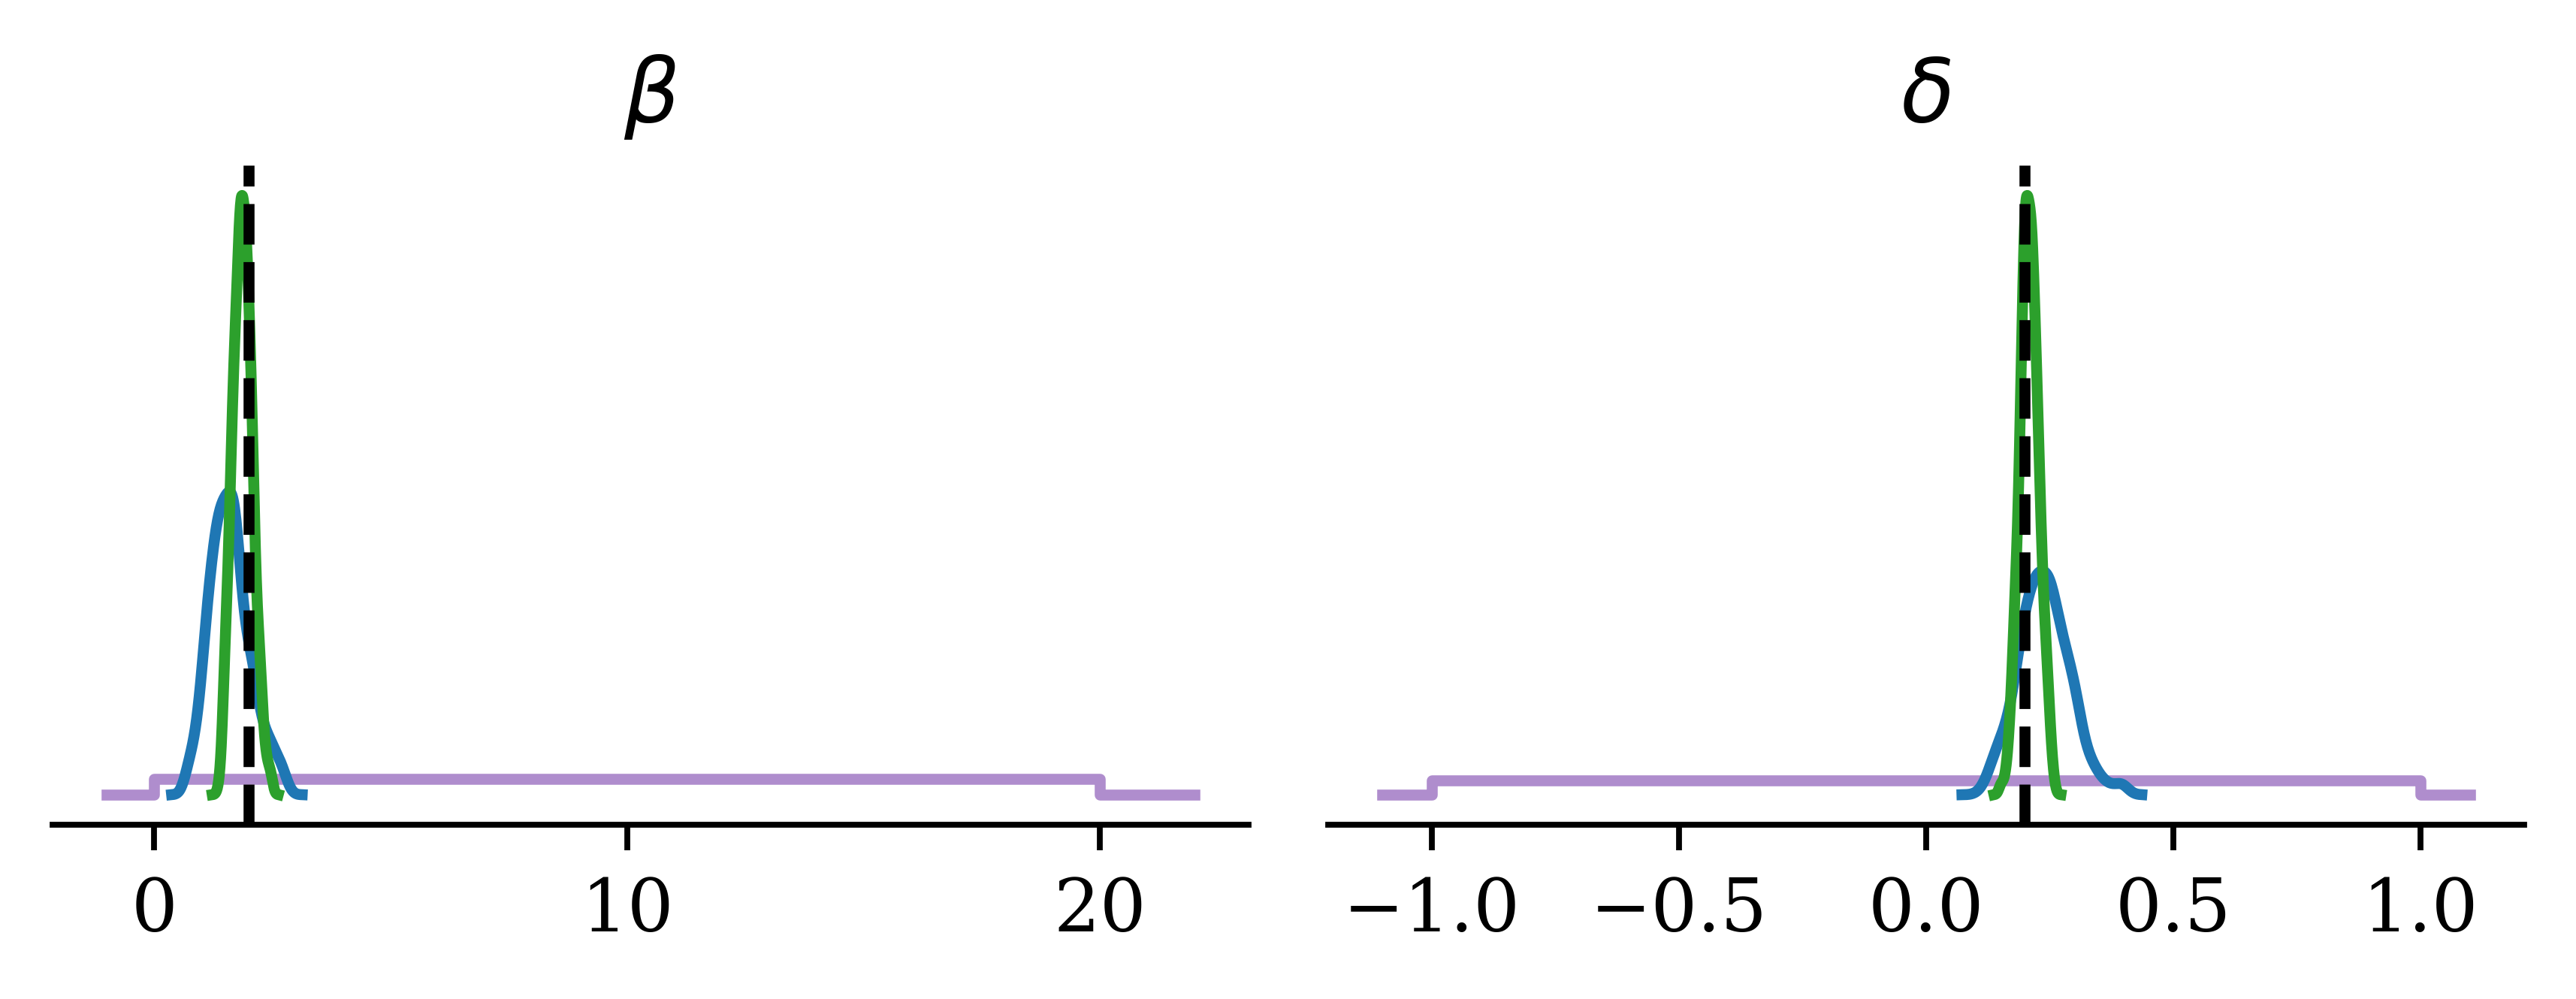

In [18]:
fig, axs = plt.subplots(1, len(params), tight_layout=True)

for l in range(len(params)):
    pLims = [prior.marginals[l].isf(1), prior.marginals[l].isf(0)]

    for k, ss in enumerate(sample_sizes):
        sampleData = dfABC_freq.query("ss == @ss")
        sample = sampleData[params[l]]
        weights = sampleData["weights"]

        dataResampled, xs, ys = abc.resample_and_kde(sample, weights, clip=pLims)
        axs[l].plot(xs, ys, label="ABC")

    axs[l].axvline(θ_sev[l], **trueStyle)
    axs[l].set_title("$" + params[l] + "$")
    axs[l].set_yticks([])

draw_prior(prior, axs)
sns.despine(left=True)
# save_cropped("../Figures/hist-test2-poisson-depexp-freq.pdf")

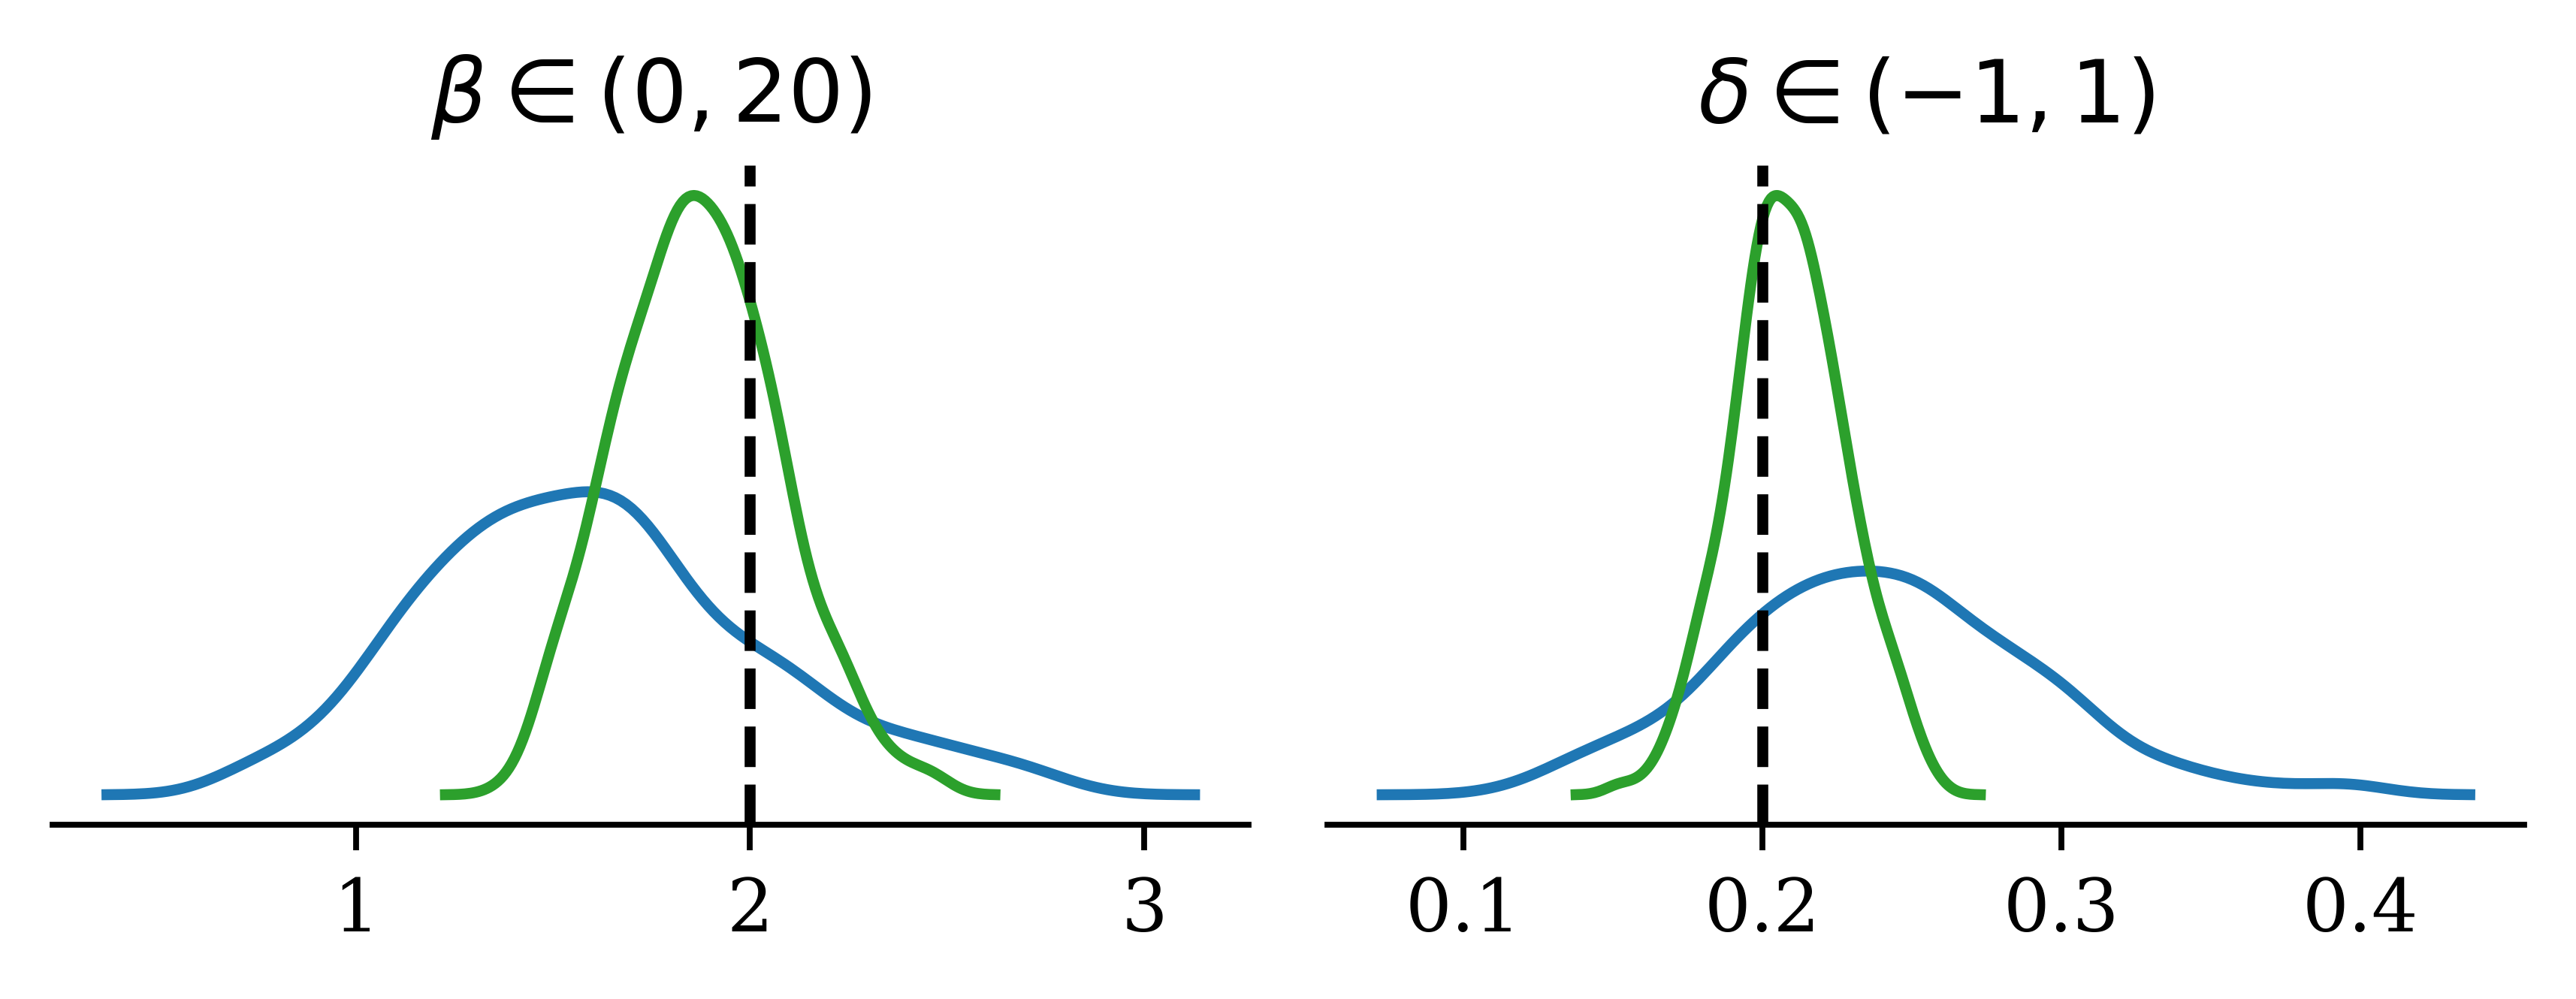

In [19]:
fig, axs = plt.subplots(1, len(params), tight_layout=True)

for l in range(len(params)):
    pLims = [prior.marginals[l].isf(1), prior.marginals[l].isf(0)]

    for k, ss in enumerate(sample_sizes):
        sampleData = dfABC_freq.query("ss == @ss")
        sample = sampleData[params[l]]
        weights = sampleData["weights"]

        dataResampled, xs, ys = abc.resample_and_kde(sample, weights, clip=pLims)
        axs[l].plot(xs, ys, label="ABC")

    axs[l].axvline(θ_sev[l], **trueStyle)
    axs[l].set_title("$" + params[l] + f"\\in ({pLims[0]:.0f}, {pLims[1]:.0f})$")
    axs[l].set_yticks([])

sns.despine(left=True)
# save_cropped("../Figures/hist-test2-poisson-depexp-freq-zoomed.pdf")

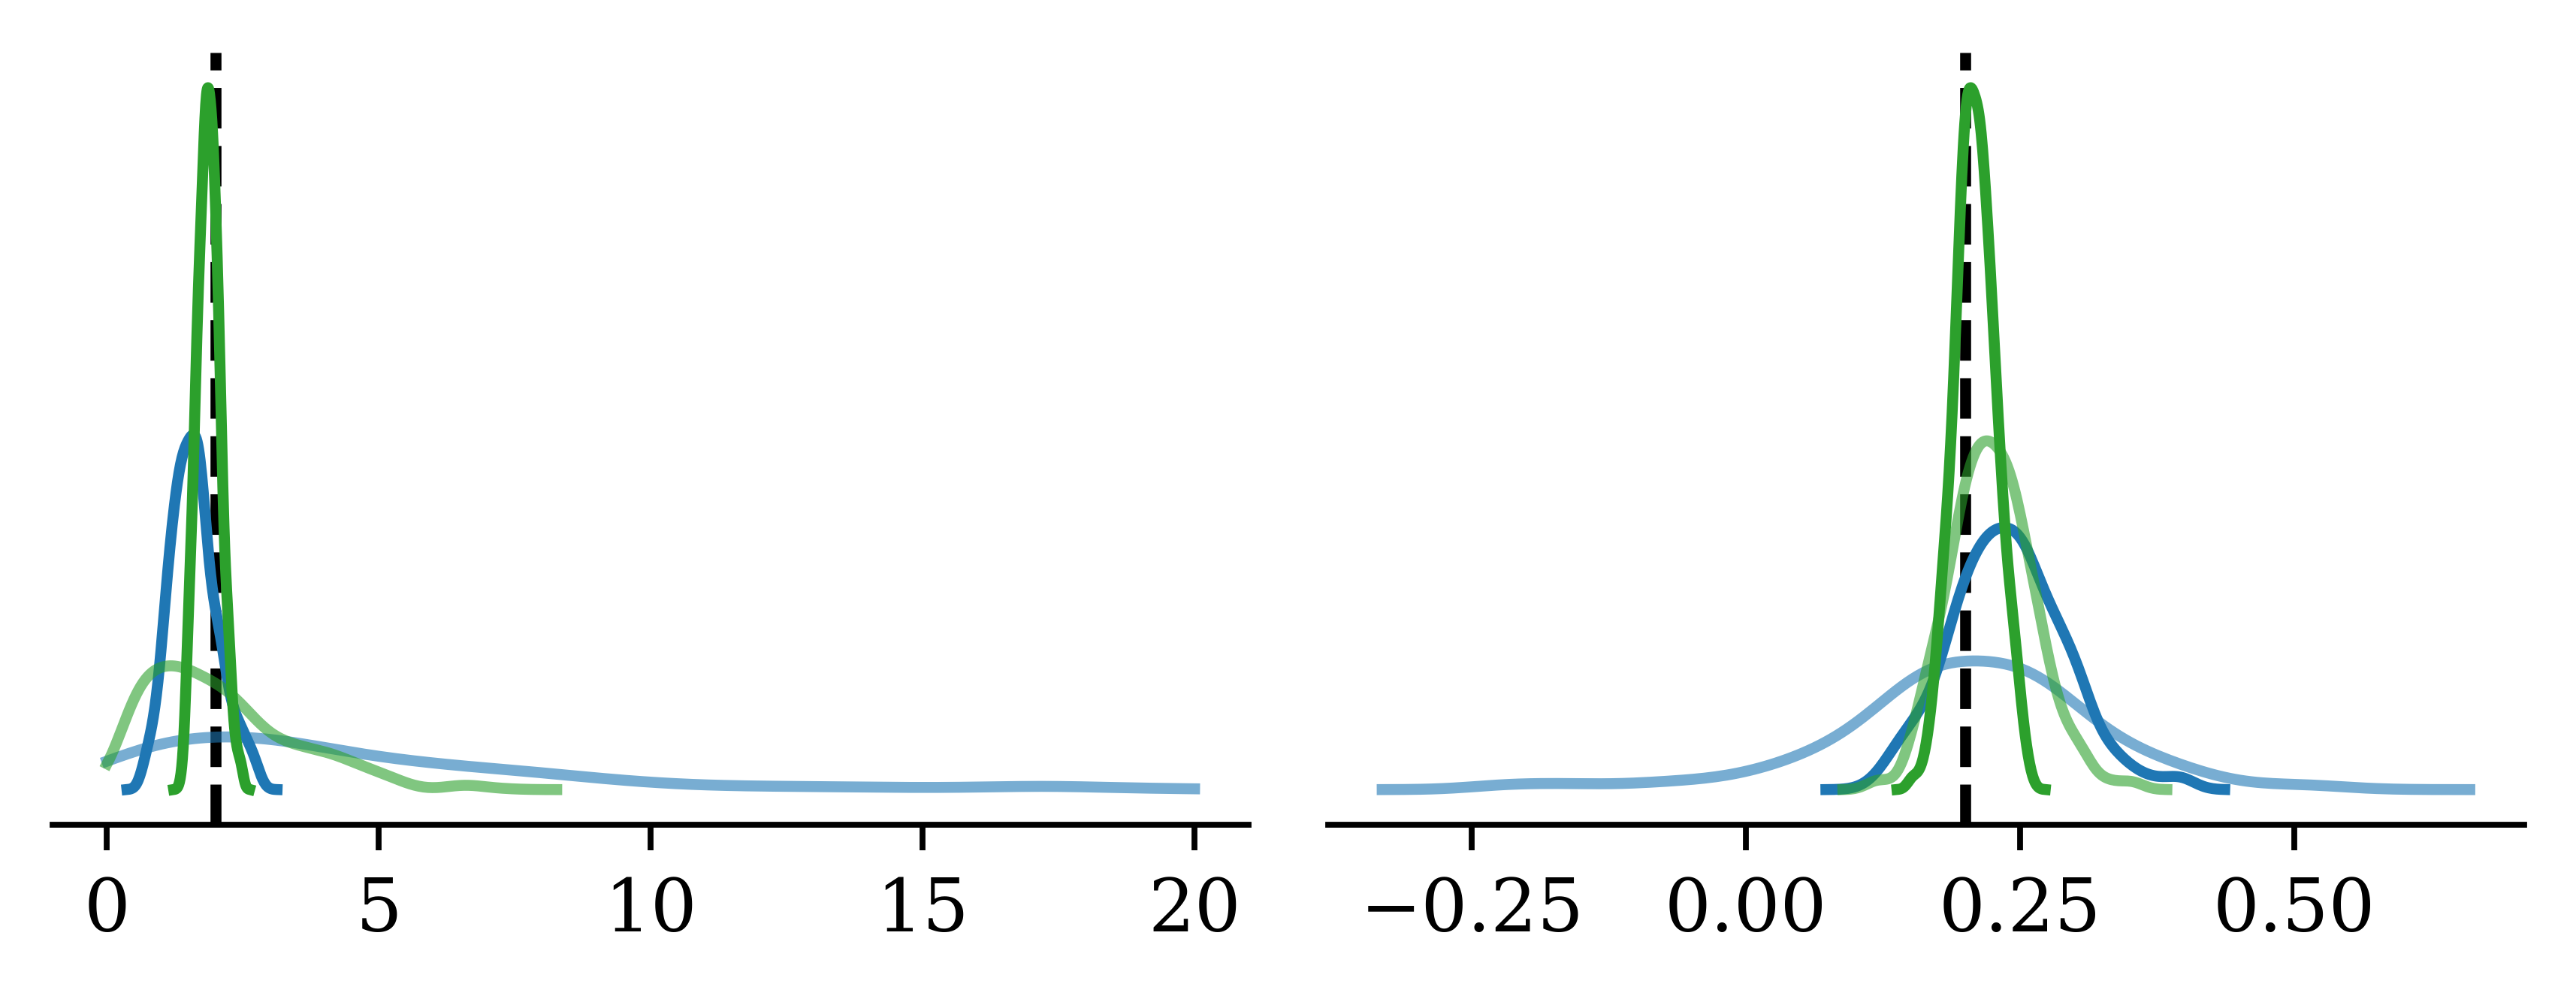

In [20]:
fig, axs = plt.subplots(1, len(params), tight_layout=True)

alphas = (0.6, 1)

for l in range(len(params)):
    pLims = [prior.marginals[l].isf(1), prior.marginals[l].isf(0)]

    axs[l].axvline(θ_sev[l], **trueStyle)
    axs[l].set_yticks([])
    for k, ss in enumerate(sample_sizes):

        for j, df in enumerate((dfABC, dfABC_freq)):
            sampleData = df.query("ss == @ss")
            sample = sampleData[params[l]]
            weights = sampleData["weights"]

            dataResampled, xs, ys = abc.resample_and_kde(sample, weights, clip=pLims)
            axs[l].plot(xs, ys, label="ABC", alpha=alphas[j], c=colors[k])

            # axs[l].set_title("$" + params[l] + "$")

sns.despine(left=True)
# save_cropped("../Figures/hist-test2-poisson-depexp-both.pdf")

/tmp/ipykernel_12130/953721773.py:28: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


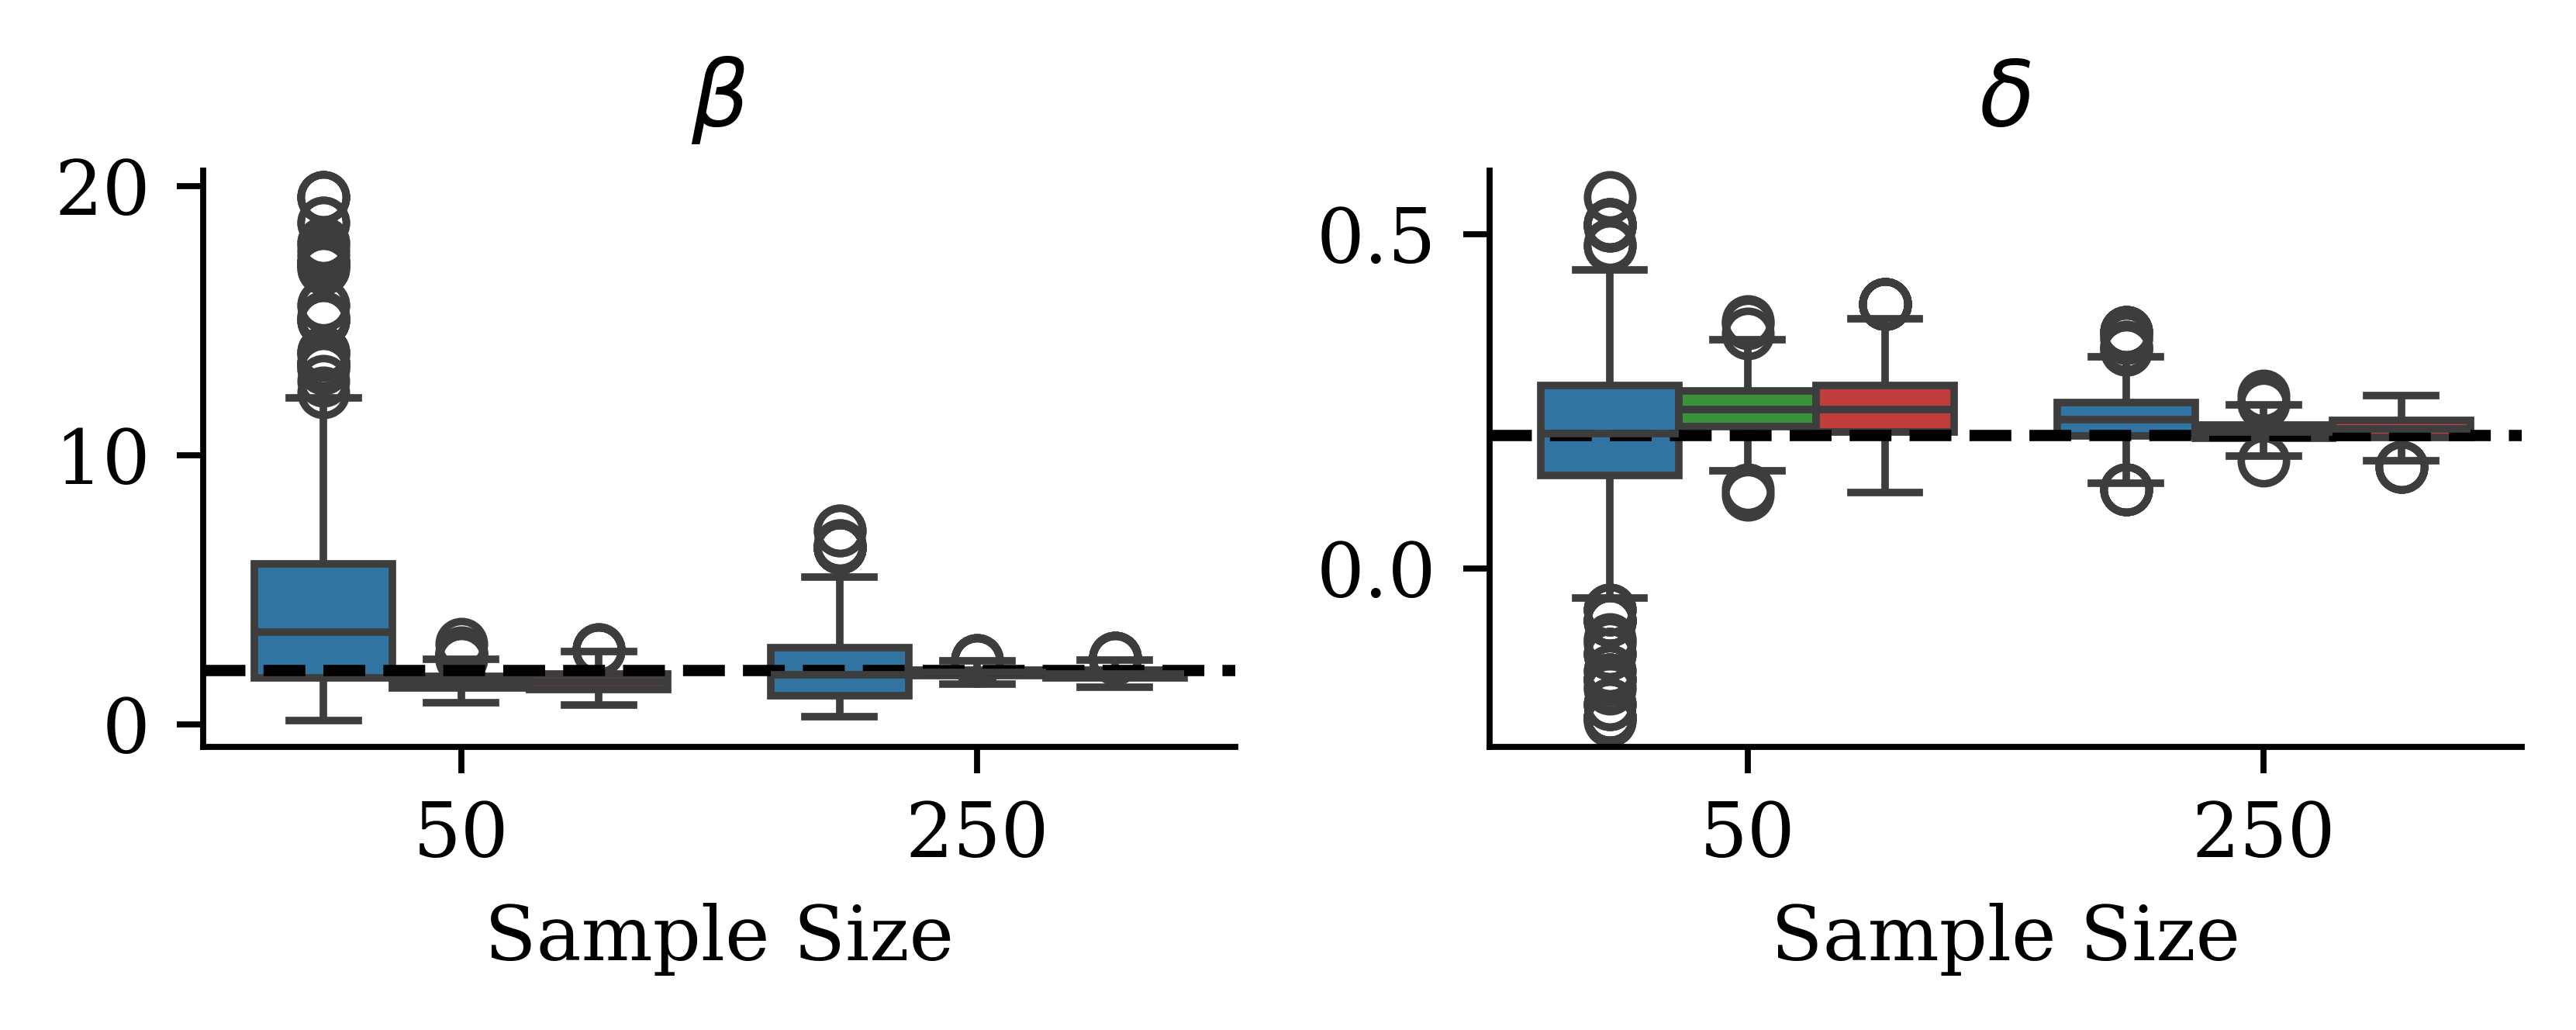

In [21]:
rg = default_rng(1234)

resampled_post_ABC_freq = pd.DataFrame(
    {"ss": np.concatenate([np.repeat(ss, popSize * n_resample) for ss in sample_sizes])}
)

for l in range(len(params)):
    res_param = np.array([])
    for ss in sample_sizes:
        sampleData = dfABC_freq.query("ss == @ss")
        sample = sampleData[params[l]]
        weights = sampleData["weights"]

        dataResampled = sample[abc.resample(rg, weights, repeats=n_resample)]
        res_param = np.concatenate([res_param, dataResampled])

    resampled_post_ABC_freq[params[l]] = res_param

resampled_post_ABC_freq["posterior"] = np.repeat(
    "ABC with freq.", len(sample_sizes) * popSize * n_resample
)
dfV2 = pd.concat([post_samples, resampled_post_ABC_freq], axis=0)

dfV2["ss"] = dfV2["ss"].astype(np.int64)

for l in range(len(params)):
    plt.subplot(1, len(params), l + 1)
    plt.tight_layout()
    sns.boxplot(x="ss", y=params[l], hue="posterior", data=dfV2)
    plt.gca().axhline(θ_sev[l], **trueStyle)
    plt.title("$" + params[l] + "$")
    plt.ylabel("")
    plt.xlabel("Sample Size")
    plt.legend("", frameon=False)

sns.despine()
# save_cropped("../Figures/boxplot-test2-poisson-depexp-freq.pdf")

In [22]:
elapsed = toc()
print(f"Notebook time = {elapsed:.0f} secs = {elapsed/60:.2f} mins")

Notebook time = 1135 secs = 18.92 mins


In [23]:
dill.dump_session("Sim_Poisson_Depexp.pkl")